In [1]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [4]:
df

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785736,Software Engineer,DevOps Engineer,Singapura,melalui Trabajo.org,Pekerjaan tetap,False,Singapore,2023-03-13 06:16:16,False,False,Singapore,NaN,NaN,NaN,CAREERSTAR INTERNATIONAL PTE. LTD.,"[bash, python, perl, linux, unix, kubernetes, ...","{'os': ['linux', 'unix'], 'other': ['kubernete..."
785737,Data Analyst,CRM Data Analyst,"Bad Rodach, Jerman",melalui BeBee Deutschland,Pekerjaan tetap,False,Germany,2023-03-12 06:18:18,False,False,Germany,NaN,NaN,NaN,HABA FAMILYGROUP,"[sas, sas, sql, excel]","{'analyst_tools': ['sas', 'excel'], 'programmi..."
785738,Business Analyst,Commercial Analyst - Start Now,Malaysia,melalui Ricebowl,Pekerjaan tetap,False,Malaysia,2023-03-12 06:32:36,False,False,Malaysia,NaN,NaN,NaN,Lendlease Corporation,"[powerpoint, excel]","{'analyst_tools': ['powerpoint', 'excel']}"
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,"[python, go, nosql, sql, mongo, shell, mysql, ...","{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."


fig, ax = plt.subplots() creates a blank plot layout in Matplotlib by initializing the overall window/canvas (fig) and the individual plot grid (ax) at the exact same time.

Component Breakdown
plt: The standard shorthand alias for matplotlib.pyplot, the module used to draw plots in Python.

.subplots(): A Matplotlib function that builds a Figure and one or more Axes objects in a single command. By default (with no arguments inside ()), it creates 1 figure with 1 plot area inside it.

fig (Figure): The overall canvas/page. It acts as the top-level container holding everything together—including figure dimensions (figsize), background colors, and any subplots inside.

ax (Axes): The actual individual chart/graph box. This object holds the x-axis, y-axis, grid lines, data series (bars, lines, scatter points), axis labels, and title.

fig, ax = (Tuple Unpacking): .subplots() returns a tuple containing (Figure, Axes). Python unpacks the two objects into the variables fig and ax simultaneously.

In [11]:
df["job_title_short"].value_counts()

job_title_short
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Business Analyst              49063
Software Engineer             44929
Senior Data Engineer          44563
Senior Data Scientist         36957
Senior Data Analyst           29216
Machine Learning Engineer     14080
Cloud Engineer                12331
Name: count, dtype: int64

In [15]:
df["job_schedule_type"].value_counts().head(3)

job_schedule_type
Full-time     701727
Contractor     34793
Internship      8742
Name: count, dtype: int64

<Axes: xlabel='job_schedule_type'>

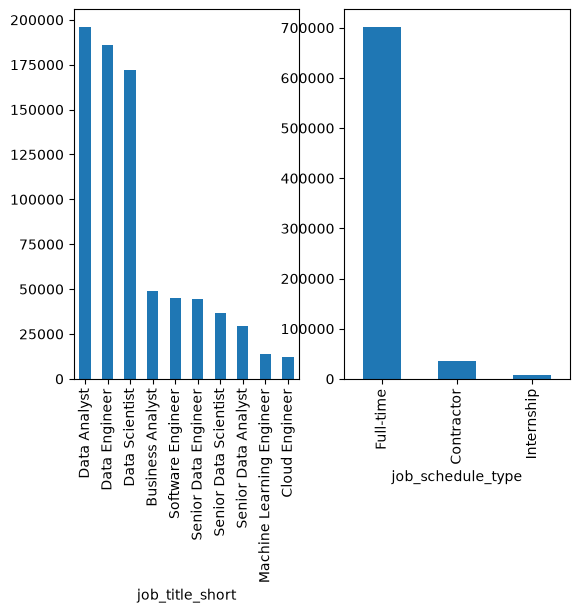

In [ ]:
# subplot functions to graph everything in one single figure

fig, ax = plt.subplots(1,2) # 1 page 2 graphs or 1 row 2 columns of graph; ax is the individual plot, fig is the area they are in

df["job_title_short"].value_counts().plot(kind="bar", ax=ax[0]) # we need to speicfy the index of ax we are using

df["job_schedule_type"].value_counts().head(3).plot(kind="bar", ax=ax[1])

<Axes: xlabel='job_schedule_type'>

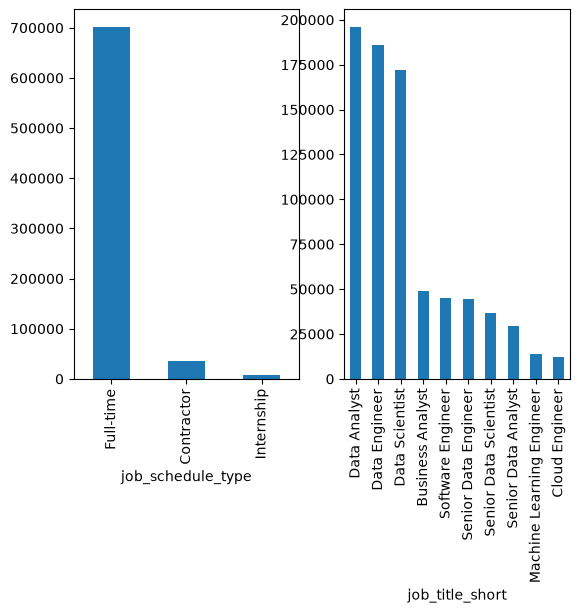

In [20]:
# we can switch order
fig, ax = plt.subplots(1,2)
df["job_title_short"].value_counts().plot(kind="bar", ax=ax[1]) 

df["job_schedule_type"].value_counts().head(3).plot(kind="bar", ax=ax[0])

Note: we can see the overlaps of two graphs, we can solve by the function tight_layout - we want to apply this fucntion onto the entire figure

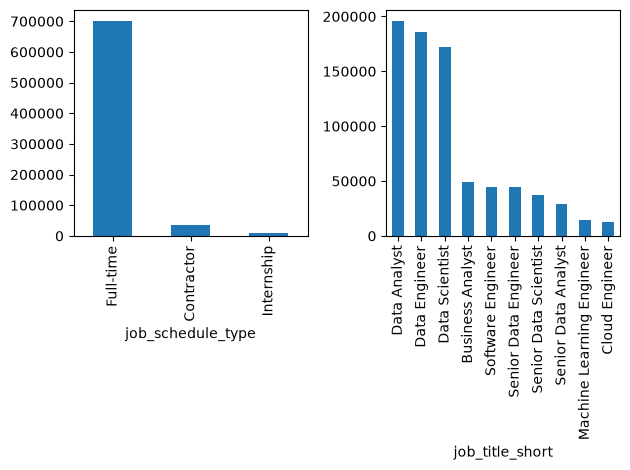

In [21]:
fig, ax = plt.subplots(1,2)
df["job_title_short"].value_counts().plot(kind="bar", ax=ax[1]) 

df["job_schedule_type"].value_counts().head(3).plot(kind="bar", ax=ax[0])

fig.tight_layout()

### Example: Counts of Top Skills in Job Postings

In [ ]:
df_skills = df.copy()
df_skills = df_skills.explode("job_skills")
skills_count = df_skills.groupby(["job_skills", "job_title_short"]).size()
df_skills_count = df_skills.groupby(["job_skills", "job_title_short"]).size().reset_index(name="skill_count") # reset_index to make dataframe, name is the name of the new column that appears sue to reset_index
df_skills_count.sort_values(by="skill_count", ascending=False, inplace=True) # or we could define new dataframe w/o  the inplace df_skills_count_final = df_skills_count.sort_values(by="skill_count", ascending=False)
df_skills_count

,job_skills,job_title_short,skill_count
1480,python,Data Scientist,113711
1822,sql,Data Engineer,113130
1479,python,Data Engineer,108022
1821,sql,Data Analyst,92428
1823,sql,Data Scientist,78982
...,...,...,...
2173,webex,Senior Data Scientist,1
293,codecommit,Business Analyst,1
2233,xamarin,Machine Learning Engineer,1
1087,mlr,Machine Learning Engineer,1


In [ ]:
job_titles = ["Data Scientist", "Data Engineer", "Data Analyst"] # we are gonna loop through each one to extract 

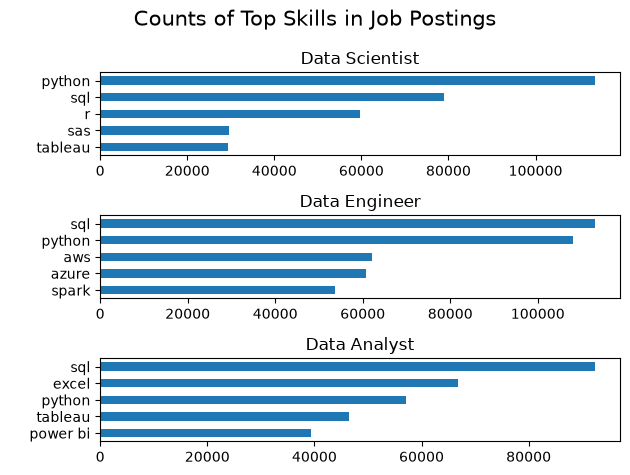

In [ ]:
fig, ax = plt.subplots(3, 1) # 3 rows and 1 column

for i, job_title in enumerate(job_titles): # index and actual value
    df_plot = df_skills_count[df_skills_count["job_title_short"] == job_title].head()
    df_plot.plot(kind="barh", x = "job_skills", y="skill_count", ax=ax[i], title=job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel(" ")
    ax[i].legend().set_visible(False)


fig.suptitle("Counts of Top Skills in Job Postings", fontsize=15)

fig.tight_layout()

# note that the x-axis scale is not the same for the 3 plots and thus incomparable

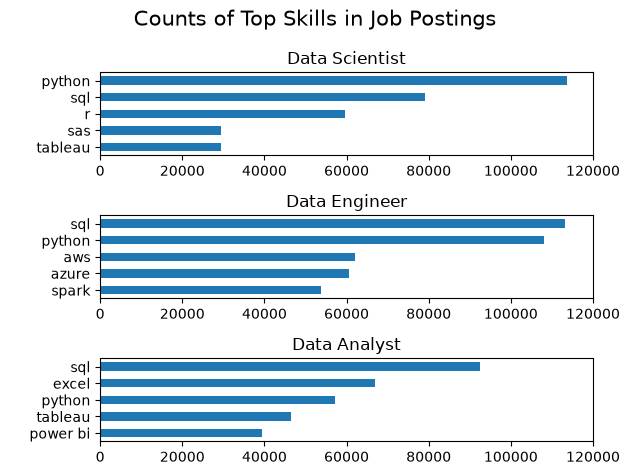

In [37]:
fig, ax = plt.subplots(3, 1) # 3 rows and 1 column

for i, job_title in enumerate(job_titles): # index and actual value
    df_plot = df_skills_count[df_skills_count["job_title_short"] == job_title].head()
    df_plot.plot(kind="barh", x = "job_skills", y="skill_count", ax=ax[i], title=job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel(" ")
    ax[i].legend().set_visible(False)
    ax[i].set_xlim(0, 120_000) # indicate lowest and highst values acceptable


fig.suptitle("Counts of Top Skills in Job Postings", fontsize=15)

fig.tight_layout()